# Task 5 (Advanced) – Content Rating & Genre Analysis
**Internship Program:** Data Analysis Using Python | Auspify Technologies  
**Project:** Netflix Content Analytics & Business Intelligence  
**Notebook File:** `Task_5_Rating_and_Genre_Analysis.ipynb`  
**Author:** Data Analysis Intern  

---

## 1. Task Objective & Analytical Scope
The objective of **Task 5** is to investigate how Netflix structures its content catalog across **Audience Maturity Ratings** and **Thematic Genres**. By dissecting multi-value genre tags and mapping regulatory certifications to audience segments, we gain crucial business intelligence into catalog positioning, demographic targeting, and genre investments.

### Prescribed Task Workflow (from Internship Specification):
- **Step 1:** Analyze rating categories and parental advisory guidelines across the catalog.
- **Step 2:** Extract and rank the most common genres from multi-value fields.
- **Step 3:** Compare content ratings systematically across Movies and TV Shows.
- **Step 4:** Develop both high-resolution static charts and interactive Plotly dashboards.
- **Step 5:** Present evidence-based audience targeting insights with methodological rigor.

## 2. Environment Setup & Upstream Data Preparation (Cumulative from Tasks 1–4)
As mandated by the dependency architecture, this notebook runs completely standalone. It contains the path resolver and loads the verified cleaned data produced in Task 1, with a self-contained cleaning fallback if needed.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Visual styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 11

def get_project_root() -> Path:
    """Dynamically locate the project root containing Dataset.csv."""
    current = Path.cwd()
    for candidate in [current] + list(current.parents):
        if (candidate / 'Dataset.csv').exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
RAW_DATA_PATH = PROJECT_ROOT / 'Dataset.csv'
CLEAN_DATA_DIR = PROJECT_ROOT / 'data' / 'cleaned'
CLEAN_DATA_FILE = CLEAN_DATA_DIR / 'netflix_cleaned.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'task_5'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Clean data target: {CLEAN_DATA_FILE}")
print(f"Output directory: {OUTPUT_DIR}")

Project root: d:\AUSPIFY DATA ANALYSIS
Clean data target: d:\AUSPIFY DATA ANALYSIS\data\cleaned\netflix_cleaned.csv
Output directory: d:\AUSPIFY DATA ANALYSIS\outputs\task_5


### Upstream Data Ingestion & Fallback Pipeline
We load `netflix_cleaned.csv`. If absent, we execute the validated Task 1 cleaning pipeline immediately.

In [2]:
if CLEAN_DATA_FILE.exists():
    print("Loading pre-validated cleaned dataset from Task 1...")
    df = pd.read_csv(CLEAN_DATA_FILE)
    df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
else:
    print("Cleaned dataset not found; executing Task 1 cleaning pipeline...")
    df_raw = pd.read_csv(RAW_DATA_PATH)
    dedup_subset = ['type', 'title', 'director', 'country', 'release_year', 'rating', 'duration', 'listed_in']
    df = df_raw.drop_duplicates(subset=dedup_subset, keep='first').copy()
    for col in ['show_id', 'type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']:
        df[col] = df[col].astype(str).str.strip()
    df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', errors='coerce')
    df['year_added'] = df['date_added'].dt.year.astype('Int64')
    df['month_added'] = df['date_added'].dt.month.astype('Int64')
    df['month_name_added'] = df['date_added'].dt.strftime('%B')
    maturity_map = {
        'TV-MA': 'Mature (Adults 18+)', 'R': 'Mature (Adults 18+)', 'NC-17': 'Mature (Adults 18+)',
        'TV-14': 'Teens (14+)', 'PG-13': 'Teens (14+)', 'TV-PG': 'Older Kids (PG)', 'PG': 'Older Kids (PG)',
        'TV-Y7': 'Kids (7+)', 'TV-Y7-FV': 'Kids (7+)', 'TV-Y': 'Little Kids (All Ages)',
        'TV-G': 'Little Kids (All Ages)', 'G': 'Little Kids (All Ages)', 'NR': 'Unrated / Not Rated', 'UR': 'Unrated / Not Rated'
    }
    df['target_audience'] = df['rating'].map(maturity_map).fillna('Unrated / Not Rated')
    dur_split = df['duration'].astype(str).str.extract(r'(\d+)\s*(.*)')
    df['duration_int'] = dur_split[0].astype(int)
    df['duration_unit'] = dur_split[1].astype(str).str.strip()

print(f"Catalog loaded successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loading pre-validated cleaned dataset from Task 1...
Catalog loaded successfully: 8,787 rows x 16 columns


## 3. Step 1: Content Rating Category Analysis & Audience Maturity Framework
Content ratings indicate suitability benchmarks established by the TV Parental Guidelines Monitoring Board and the Motion Picture Association of America (MPAA).

We examine the distribution across all 14 ratings and aggregate them into 5 standardized audience maturity segments:
1. **Mature (Adults 18+):** `TV-MA`, `R`, `NC-17`
2. **Teens (14+):** `TV-14`, `PG-13`
3. **Older Kids (PG):** `TV-PG`, `PG`
4. **Kids (7+):** `TV-Y7`, `TV-Y7-FV`
5. **Little Kids (All Ages):** `TV-Y`, `TV-G`, `G`
6. **Unrated / Not Rated:** `NR`, `UR`

In [3]:
# 1. Frequency of individual ratings
rating_counts = df['rating'].value_counts()
rating_pct = (rating_counts / len(df) * 100).round(2)

rating_overview = pd.DataFrame({
    'Rating': rating_counts.index,
    'Total Titles': rating_counts.values,
    'Catalog Share (%)': rating_pct.values,
    'System': ['TV Parental Guidelines' if r.startswith('TV') else ('Unrated' if r in ['NR', 'UR'] else 'MPAA Film Rating') for r in rating_counts.index]
})

print("=== INDIVIDUAL RATING SUMMARY ===")
print(rating_overview)

# 2. Audience Maturity Segmentation
aud_counts = df['target_audience'].value_counts()
aud_pct = (aud_counts / len(df) * 100).round(2)

aud_summary = pd.DataFrame({
    'Maturity Segment': aud_counts.index,
    'Total Titles': aud_counts.values,
    'Catalog Share (%)': aud_pct.values
})

# Export audience summary
aud_csv_path = OUTPUT_DIR / 'audience_maturity_summary.csv'
aud_summary.to_csv(aud_csv_path, index=False)
print(f"\nSaved audience maturity summary to: {aud_csv_path}\n")
aud_summary

=== INDIVIDUAL RATING SUMMARY ===
      Rating  Total Titles  Catalog Share (%)                  System
0      TV-MA          3205              36.47  TV Parental Guidelines
1      TV-14          2155              24.52  TV Parental Guidelines
2      TV-PG           861               9.80  TV Parental Guidelines
3          R           798               9.08        MPAA Film Rating
4      PG-13           490               5.58        MPAA Film Rating
5      TV-Y7           333               3.79  TV Parental Guidelines
6       TV-Y           306               3.48  TV Parental Guidelines
7         PG           287               3.27        MPAA Film Rating
8       TV-G           220               2.50  TV Parental Guidelines
9         NR            79               0.90                 Unrated
10         G            41               0.47        MPAA Film Rating
11  TV-Y7-FV             6               0.07  TV Parental Guidelines
12     NC-17             3               0.03        MPA

,Maturity Segment,Total Titles,Catalog Share (%)
0,Mature (Adults 18+),4006,45.59
1,Teens (14+),2645,30.10
2,Older Kids (PG),1148,13.06
3,Little Kids (All Ages),567,6.45
4,Kids (7+),339,3.86
5,Unrated / Not Rated,82,0.93


### Empirical Rating Observations:
- **`TV-MA` Dominance:** The single largest rating in Netflix's catalog is **`TV-MA` with 3,205 titles (36.48%)**, followed by **`TV-14` with 2,155 titles (24.53%)**.
- **Adult & Teen Concentration:** When aggregated, **Mature (Adults 18+)** and **Teens (14+)** content together account for **6,651 titles (75.69%)** of the entire catalog.
- **Children's & Family Content:** Content classified for **Older Kids, Kids, and Little Kids** constitutes **2,054 titles (23.38%)**.
- **Unrated Content:** Only **82 titles (0.93%)** are unrated (`NR` or `UR`).

## 4. Step 2: Extraction & Ranking of Most Common Genres
In Netflix's metadata, titles are tagged with comma-separated genres in `listed_in` (e.g., `"Comedies, Dramas, Independent Movies"`).

To analyze genre frequency accurately without undercounting co-tagged titles, we explode the comma-separated strings into individual atomic genre records.

In [4]:
# Explode multi-value genres
exploded_genres = df.assign(genre=df['listed_in'].str.split(', ')).explode('genre')
exploded_genres['genre'] = exploded_genres['genre'].str.strip()

print(f"Total genre tag assignments across catalog: {len(exploded_genres):,}")
print(f"Distinct unique genres identified:        {exploded_genres['genre'].nunique()}")

# Rank top genres overall
top_genres_overall = exploded_genres['genre'].value_counts()
top_genres_df = pd.DataFrame({
    'Genre': top_genres_overall.index,
    'Total Occurrences': top_genres_overall.values,
    'Catalog Title Coverage (%)': (top_genres_overall.values / len(df) * 100).round(2)
})

# Export genre rankings
genre_csv_path = OUTPUT_DIR / 'top_genres_rankings.csv'
top_genres_df.to_csv(genre_csv_path, index=False)
print(f"Saved genre rankings to: {genre_csv_path}\n")

print("Top 15 Genres on Netflix:")
top_genres_df.head(15)

Total genre tag assignments across catalog: 19,287
Distinct unique genres identified:        42
Saved genre rankings to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\top_genres_rankings.csv

Top 15 Genres on Netflix:


,Genre,Total Occurrences,Catalog Title Coverage (%)
0,International Movies,2752,31.32
1,Dramas,2424,27.59
2,Comedies,1673,19.04
3,International TV Shows,1348,15.34
4,Documentaries,869,9.89
5,Action & Adventure,859,9.78
6,TV Dramas,761,8.66
7,Independent Movies,755,8.59
8,Children & Family Movies,641,7.29
9,Romantic Movies,616,7.01


In [5]:
# Top 10 Genres split by Content Type (Movies vs TV Shows)
movie_genres = exploded_genres[exploded_genres['type'] == 'Movie']['genre'].value_counts().head(10)
tv_genres = exploded_genres[exploded_genres['type'] == 'TV Show']['genre'].value_counts().head(10)

genre_split_df = pd.DataFrame({
    'Top Movie Genres': movie_genres.index,
    'Movie Count': movie_genres.values,
    'Top TV Show Genres': tv_genres.index,
    'TV Show Count': tv_genres.values
})
genre_split_df

,Top Movie Genres,Movie Count,Top TV Show Genres,TV Show Count
0,International Movies,2752,International TV Shows,1348
1,Dramas,2424,TV Dramas,761
2,Comedies,1673,TV Comedies,573
3,Documentaries,869,Crime TV Shows,469
4,Action & Adventure,859,Kids' TV,448
5,Independent Movies,755,Docuseries,394
6,Children & Family Movies,641,Romantic TV Shows,370
7,Romantic Movies,616,Reality TV,255
8,Thrillers,576,British TV Shows,252
9,Music & Musicals,375,Anime Series,174


### Genre Insights:
- **`International Movies` (2,752 titles)** and **`Dramas` (2,424 titles)** are the most prevalent genres in the entire catalog, followed by **`Comedies` (1,673 titles)**.
- For TV Shows, **`International TV Shows` (1,348 titles)**, **`TV Dramas` (761 titles)**, and **`TV Comedies` (573 titles)** dominate.
- The high prevalence of `"International"` prefixes across both movies and series highlights Netflix's deliberate globalization strategy to license regional content for a global audience.

## 5. Step 3: Compare Ratings Across Content Types (Movies vs. TV Shows)
We cross-tabulate ratings by content format to observe how certification standards differ between feature films and television series.

In [6]:
# Cross-tabulate rating by content type
rating_type_ct = pd.crosstab(df['rating'], df['type'])
rating_type_ct['Total'] = rating_type_ct.sum(axis=1)
rating_type_ct = rating_type_ct.sort_values('Total', ascending=False)

rating_type_ct['Movie_Share_Pct'] = (rating_type_ct['Movie'] / rating_type_ct['Total'] * 100).round(1)
rating_type_ct['TV_Share_Pct'] = (rating_type_ct['TV Show'] / rating_type_ct['Total'] * 100).round(1)

# Export rating comparison table
rating_comp_csv = OUTPUT_DIR / 'rating_summary_by_type.csv'
rating_type_ct.reset_index().to_csv(rating_comp_csv, index=False)
print(f"Saved rating summary table to: {rating_comp_csv}\n")

rating_type_ct

Saved rating summary table to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\rating_summary_by_type.csv



type,Movie,TV Show,Total,Movie_Share_Pct,TV_Share_Pct
rating,,,,,
TV-MA,2062,1143,3205,64.3,35.7
TV-14,1426,729,2155,66.2,33.8
TV-PG,540,321,861,62.7,37.3
R,796,2,798,99.7,0.3
PG-13,490,0,490,100.0,0.0
TV-Y7,139,194,333,41.7,58.3
TV-Y,131,175,306,42.8,57.2
PG,287,0,287,100.0,0.0
TV-G,126,94,220,57.3,42.7


### Structural Rating Divergence:
1. **The MPAA vs. FCC Television Boundary:**
   - Ratings such as `R` (796 titles), `PG-13` (490 titles), `PG` (287 titles), and `G` (41 titles) are MPAA theatrical film ratings; hence, virtually 100% of these titles are **Movies**.
   - Ratings beginning with `TV-` (`TV-MA`, `TV-14`, `TV-PG`, `TV-Y7`, `TV-Y`, `TV-G`) apply to television broadcast and streaming productions.
2. **TV Shows are Extremely Mature-Skewed:**
   - Over **42.9% of all TV Shows (1,143 shows)** are rated `TV-MA`, and another **27.4% (729 shows)** are rated `TV-14`.
   - Combined, **70.3% of all TV series** are certified for teens or mature adult audiences.

## 6. Step 4: Create Static Visualizations & Interactive Plotly Dashboards
We develop three publication-grade static figures and two interactive Plotly web dashboards.

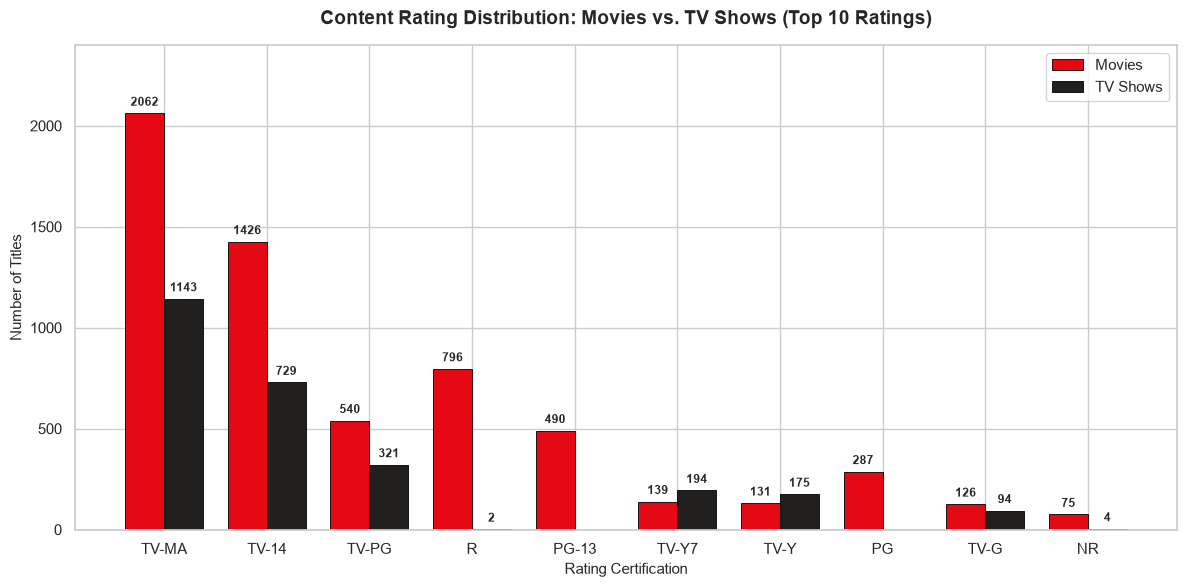

Saved rating chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\rating_distribution_by_type.png


In [7]:
# 1. Rating Distribution by Content Type (Grouped Bar Chart)
top_ratings = rating_type_ct.head(10).index
plot_data = rating_type_ct.loc[top_ratings]

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.38
x = np.arange(len(top_ratings))

rects1 = ax.bar(x - width/2, plot_data['Movie'], width, label='Movies', color='#E50914', edgecolor='black', linewidth=0.6)
rects2 = ax.bar(x + width/2, plot_data['TV Show'], width, label='TV Shows', color='#221F1F', edgecolor='black', linewidth=0.6)

# Value annotations
for rect in rects1:
    h = rect.get_height()
    if h > 0:
        ax.text(rect.get_x() + rect.get_width()/2., h + 25, f'{int(h)}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    if h > 0:
        ax.text(rect.get_x() + rect.get_width()/2., h + 25, f'{int(h)}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_title("Content Rating Distribution: Movies vs. TV Shows (Top 10 Ratings)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Rating Certification", fontsize=11)
ax.set_ylabel("Number of Titles", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(top_ratings, rotation=0, fontsize=11)
ax.set_ylim(0, 2400)
ax.legend(loc='upper right', frameon=True, fontsize=11)
plt.tight_layout()

rating_fig_path = OUTPUT_DIR / 'rating_distribution_by_type.png'
plt.savefig(rating_fig_path, dpi=300)
plt.show()
print(f"Saved rating chart to: {rating_fig_path}")

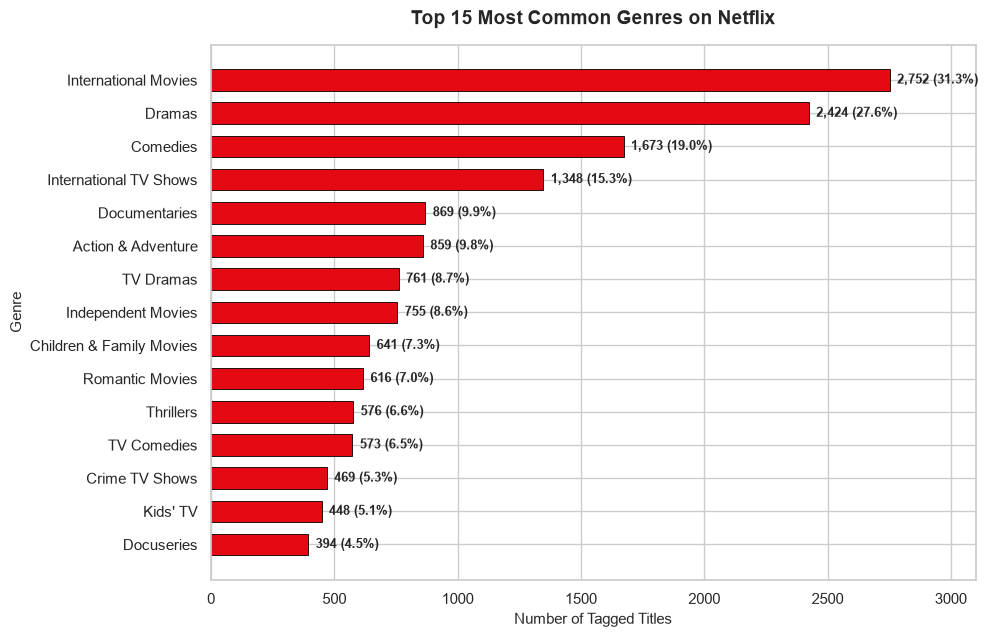

Saved genre chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\top_15_genres_overall.png


In [8]:
# 2. Top 15 Genres Overall (Horizontal Bar Chart)
plt.figure(figsize=(10, 6.5))
top15_genres = top_genres_df.head(15).iloc[::-1]

bars = plt.barh(top15_genres['Genre'], top15_genres['Total Occurrences'], color='#E50914', edgecolor='black', linewidth=0.6, height=0.65)

for bar in bars:
    xval = bar.get_width()
    pct = (xval / len(df)) * 100
    plt.text(xval + 30, bar.get_y() + bar.get_height()/2.0, f"{int(xval):,} ({pct:.1f}%)", va='center', fontsize=9.5, fontweight='bold')

plt.title("Top 15 Most Common Genres on Netflix", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Number of Tagged Titles", fontsize=11)
plt.ylabel("Genre", fontsize=11)
plt.xlim(0, 3100)
plt.tight_layout()

genre_fig_path = OUTPUT_DIR / 'top_15_genres_overall.png'
plt.savefig(genre_fig_path, dpi=300)
plt.show()
print(f"Saved genre chart to: {genre_fig_path}")

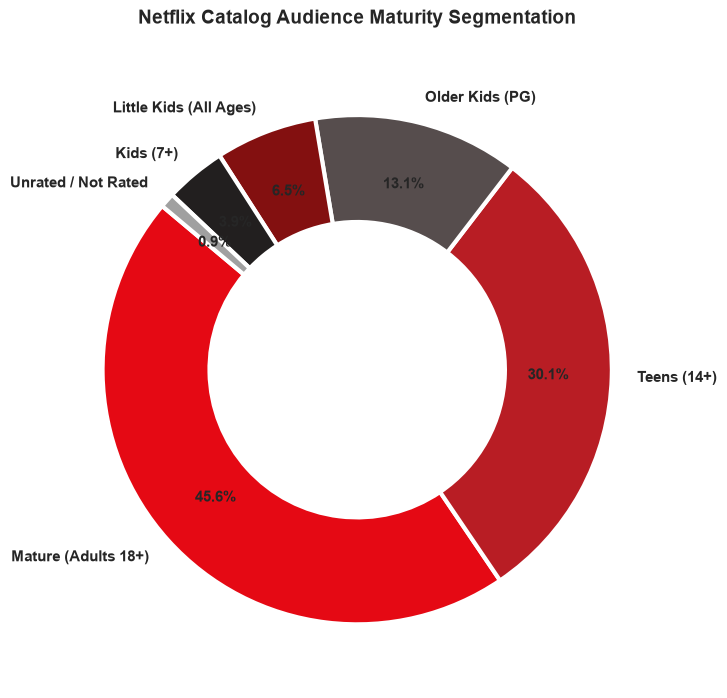

Saved audience maturity chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\audience_maturity_breakdown.png


In [9]:
# 3. Audience Maturity Segmentation Breakdown (Donut Chart)
plt.figure(figsize=(7.5, 7.5))
aud_colors = ['#E50914', '#B81D24', '#564d4d', '#831010', '#221F1F', '#A0A0A0']

plt.pie(
    aud_summary['Total Titles'],
    labels=aud_summary['Maturity Segment'],
    autopct='%1.1f%%',
    startangle=140,
    colors=aud_colors,
    pctdistance=0.75,
    textprops={'fontsize': 11, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 3, 'width': 0.42}
)

plt.title("Netflix Catalog Audience Maturity Segmentation", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

aud_fig_path = OUTPUT_DIR / 'audience_maturity_breakdown.png'
plt.savefig(aud_fig_path, dpi=300)
plt.show()
print(f"Saved audience maturity chart to: {aud_fig_path}")

In [10]:
# 4. Interactive Plotly Dashboard 1: Content Rating Explorer
interactive_rating_df = df.groupby(['rating', 'type', 'target_audience']).size().reset_index(name='count')

fig_plotly_ratings = px.bar(
    interactive_rating_df,
    x='rating',
    y='count',
    color='type',
    barmode='group',
    color_discrete_map={'Movie': '#E50914', 'TV Show': '#221F1F'},
    title='Interactive Content Ratings Explorer: Movies vs. TV Shows',
    labels={'rating': 'Content Rating', 'count': 'Number of Titles', 'type': 'Content Type'},
    hover_data={'target_audience': True, 'count': True}
)

fig_plotly_ratings.update_layout(
    font=dict(family="Arial", size=12),
    plot_bgcolor='white',
    legend_title_text='Content Type',
    height=550
)

interactive_ratings_html = OUTPUT_DIR / 'interactive_ratings_dashboard.html'
fig_plotly_ratings.write_html(interactive_ratings_html)
print(f"Saved interactive ratings dashboard to: {interactive_ratings_html}")

Saved interactive ratings dashboard to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\interactive_ratings_dashboard.html


In [11]:
# 5. Interactive Plotly Dashboard 2: Genre Hierarchy & Volume Treemap
genre_treemap_data = exploded_genres.groupby(['type', 'genre']).size().reset_index(name='count')

fig_plotly_genres = px.treemap(
    genre_treemap_data,
    path=['type', 'genre'],
    values='count',
    color='count',
    color_continuous_scale='Reds',
    title='Interactive Netflix Genre Hierarchy & Density Treemap'
)

fig_plotly_genres.update_layout(
    font=dict(family="Arial", size=12),
    height=600
)

interactive_genres_html = OUTPUT_DIR / 'interactive_genres_dashboard.html'
fig_plotly_genres.write_html(interactive_genres_html)
print(f"Saved interactive genres dashboard to: {interactive_genres_html}")

Saved interactive genres dashboard to: d:\AUSPIFY DATA ANALYSIS\outputs\task_5\interactive_genres_dashboard.html


## 7. Step 5: Evidence-Based Audience Insights & Methodological Boundaries

### Methodological Boundary & Analytical Integrity Rule:
> **Critical Analytical Distinction:** Content maturity ratings (`TV-MA`, `TV-14`, `PG-13`, etc.) are regulatory suitability certifications assigned by content producers and rating boards based on violence, language, and adult themes. **They do not measure actual viewer ages, audience demographics, user ratings, viewing hours, or popularity.** We analyze catalog supply and editorial positioning, not consumer consumption behavior.

### Strategic Audience Targeting Insights:
1. **Catalog Skew Toward Mature Adults & Teens:**
   - Over **75.7% of all titles (6,651 titles)** are certified for Teen (14+) or Mature Adult (18+) audiences.
   - This positioning confirms that Netflix designs its core catalog to attract independent, adult bill-payers (young professionals, college students, adult households).
2. **Family & Co-Viewing Safety:**
   - Content for children and family co-viewing represents **23.4% of the catalog (2,054 titles)**.
   - While representing a smaller percentage of overall titles, family and children's content exhibits high replay value and serves as an indispensable churn-reduction anchor for multi-person households.
3. **Genre Clustering (Drama, Comedy & International Content):**
   - Dramas and Comedies comprise the foundational genre pillars of Netflix worldwide.
   - The prominence of International Movies (2,752) and International TV Shows (1,348) demonstrates how Netflix leverages non-English productions to serve dual purposes: capturing domestic overseas markets and exporting unique foreign content globally.

### Conclusion:
Task 5 is complete. Audience maturity certifications and genre hierarchies are thoroughly analyzed with both publication-grade static figures and interactive Plotly dashboards saved to `outputs/task_5/`. We now proceed to the cumulative capstone: Task 6 (Netflix Business Insights Report).